# ENTREGA FINAL

Blanca Gallardo, Ferran Tubert i Agustí Costabella - 15 de febrero de 2026

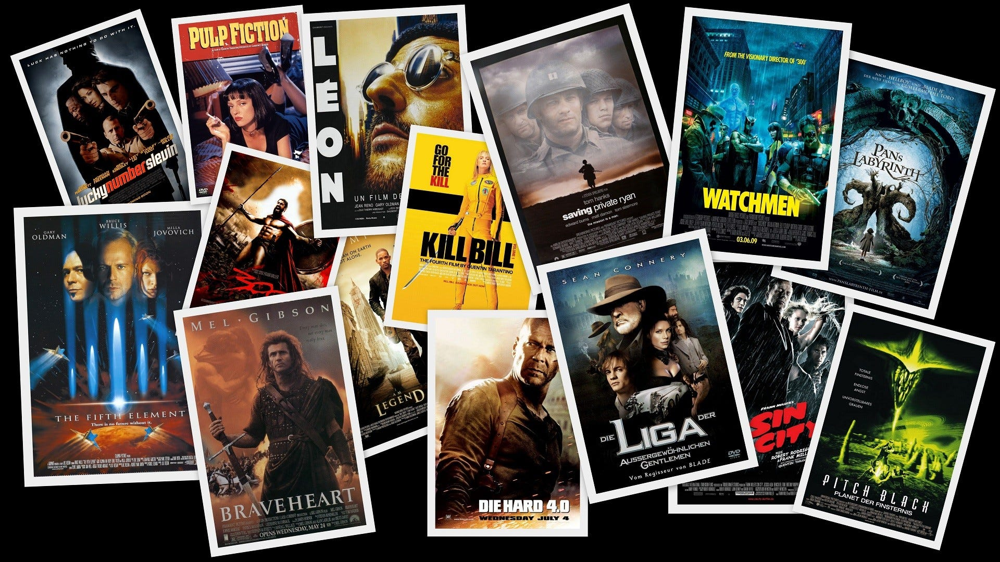
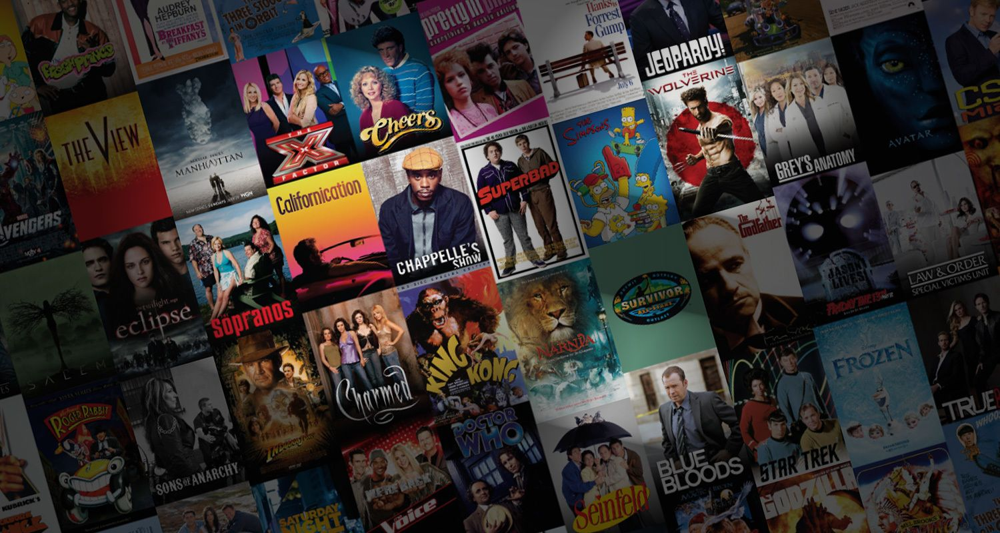
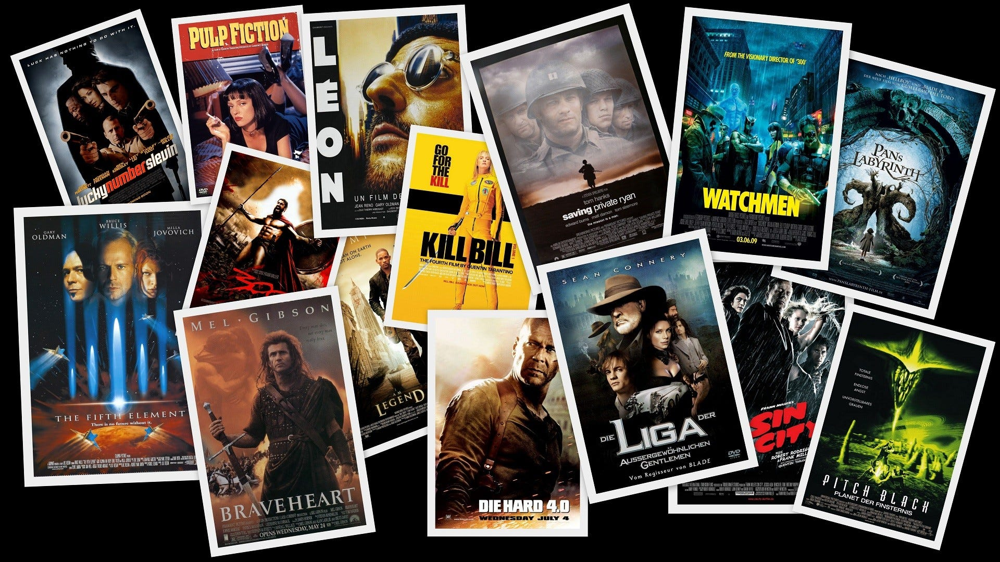

## Carga de librerías y datos

In [8]:
from src.db.MovieDatabase import MovieDatabase
import os
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
from h2o.display import display
from scipy.stats import f_oneway
from h2o.automl import H2OAutoML
import h2o

Tras cargar las librerías, importamos la base de datos y establecimos la conexión con MongoDB a través de la clase MovieDatabase, lo que nos permite acceder de manera centralizada a las colecciones de películas, géneros, compañías y países para su posterior análisis y limpieza de datos.

In [9]:
uri = os.getenv("MONGO_URI", "mongodb://localhost:59130/")
db = os.getenv("MONGO_DB", "tmdb_movies_db")

mdb = MovieDatabase(uri=uri, db_name=db)

In [10]:
# Extraer todas las colecciones
movies_docs = list(mdb.movies.find({}))
genres_docs = list(mdb.genres.find({}))
production_companies_docs = list(mdb.production_companies.find({}))
production_countries_docs = list(mdb.production_countries.find({}))
language_docs = list(mdb.languages.find({}))

# Convertir a Polars y eliminar la variable _id
movies_df = pl.from_dicts(movies_docs).drop("_id")
genres_df = pl.from_dicts(genres_docs).drop("_id")
production_companies_df = pl.from_dicts(production_companies_docs).drop("_id")
production_countries_df = pl.from_dicts(production_countries_docs).drop("_id")
language_df = pl.from_dicts(language_docs).drop("_id")

# Lazy
movies_lazy = movies_df.lazy()
genres_lazy = genres_df.lazy()
companies_lazy = production_companies_df.lazy()
countries_lazy = production_countries_df.lazy()
languages_lazy = language_df.lazy()

In [11]:
# Movies
display(movies_lazy.select(pl.all()).limit(5).collect())

# Genres
display(genres_lazy.select(pl.all()).limit(5).collect())

# Production companies
display(companies_lazy.select(pl.all()).limit(5).collect())

# Production countries
display(countries_lazy.select(pl.all()).limit(5).collect())

# Languages
display(languages_lazy.select(pl.all()).limit(5).collect())

id,title,original_title,release_date,vote_average,vote_count,popularity,runtime,original_language,revenue,overview,tagline,adult,homepage,budget,genre_ids,company_ids,country_ids,language_ids
i64,str,str,str,f64,i64,f64,i64,str,i64,str,str,bool,str,i64,list[i64],list[i64],list[i64],list[i64]
27205,"""Inception""","""Inception""","""2010-07-15""",8.364,34495,83.952,148,"""en""",825532764,"""Cobb, a skilled thief who comm…","""Your mind is the scene of the …",false,"""https://www.warnerbros.com/mov…",160000000,"[13, 7, 4]","[3939, 6165, 7444]","[79, 83]","[1, 88, … 109]"
157336,"""Interstellar""","""Interstellar""","""2014-11-05""",8.417,32571,140.241,169,"""en""",701729206,"""The adventures of a group of e…","""Mankind was born on Earth. It …",false,"""http://www.interstellarmovie.n…",165000000,"[4, 0, 7]","[3939, 6165, 5937]","[79, 83]",[1]
155,"""The Dark Knight""","""The Dark Knight""","""2008-07-16""",8.512,30619,130.643,152,"""en""",1004558444,"""Batman raises the stakes in hi…","""Welcome to a world without rul…",false,"""https://www.warnerbros.com/mov…",185000000,"[0, 13, … 9]","[4604, 3939, … 7444]","[79, 83]","[1, 110]"
19995,"""Avatar""","""Avatar""","""2009-12-15""",7.573,29815,79.932,162,"""en""",2923706026,"""In the 22nd century, a paraple…","""Enter the world of Pandora.""",false,"""https://www.avatar.com/movies/…",237000000,"[13, 4, … 7]","[4737, 2321, … 2461]","[83, 79]","[1, 56]"
24428,"""The Avengers""","""The Avengers""","""2012-04-25""",7.71,29166,98.082,143,"""en""",1518815515,"""When an unexpected enemy emerg…","""Some assembly required.""",false,"""https://www.marvel.com/movies/…",220000000,"[7, 13, 4]",[3597],[83],"[1, 69, 3]"


genre_id,name
i64,str
0,"""Drama"""
1,"""Mystery"""
2,"""Western"""
3,"""Horror"""
4,"""Adventure"""


company_id,name
i64,str
0,"""Dreams Salon Entertainment Cul…"
1,"""Lyncanthrope Films"""
2,"""Basara Pictures"""
3,"""Glass Eye Pix"""
4,"""Cosmopolitan TV"""


country_id,name
i64,str
0,"""Libyan Arab Jamahiriya"""
1,"""Cyprus"""
2,"""Kenya"""
3,"""Tunisia"""
4,"""New Zealand"""


language_id,name
i64,str
0,"""Guarani"""
1,"""English"""
2,"""Urdu"""
3,"""Russian"""
4,"""Croatian"""


## Limpieza y preparación

In [12]:
# Movies
movies_cols = movies_lazy.collect_schema().names()
movies_nulls = movies_lazy.select([
    pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in movies_cols
]).collect()
display(movies_nulls)

# Genres
genres_cols = genres_lazy.collect_schema().names()
genres_nulls = genres_lazy.select([
    pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in genres_cols
]).collect()
display(genres_nulls)

# Production Companies
companies_cols = companies_lazy.collect_schema().names()
companies_nulls = companies_lazy.select([
    pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in companies_cols
]).collect()
display(companies_nulls)

# Production Countries
countries_cols = countries_lazy.collect_schema().names()
countries_nulls = countries_lazy.select([
    pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in countries_cols
]).collect()
display(countries_nulls)

# Languages
languages_cols = languages_lazy.collect_schema().names()
languages_nulls = languages_lazy.select([
    pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in languages_cols
]).collect()
display(languages_nulls)

id_nulls,title_nulls,original_title_nulls,release_date_nulls,vote_average_nulls,vote_count_nulls,popularity_nulls,runtime_nulls,original_language_nulls,revenue_nulls,overview_nulls,tagline_nulls,adult_nulls,homepage_nulls,budget_nulls,genre_ids_nulls,company_ids_nulls,country_ids_nulls,language_ids_nulls
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


genre_id_nulls,name_nulls
u32,u32
0,0


company_id_nulls,name_nulls
u32,u32
0,0


country_id_nulls,name_nulls
u32,u32
0,0


language_id_nulls,name_nulls
u32,u32
0,0


In [13]:
# Movies
movies_duplicates = movies_lazy.select([
    pl.col("id").is_unique().alias("id_unique")
]).collect()
num_movies_duplicates = (movies_duplicates["id_unique"] == False).sum()
print(f"Duplicados en movies: {num_movies_duplicates}")

# Genres
genres_duplicates = genres_lazy.select([
    pl.col("genre_id").is_unique().alias("id_unique")
]).collect()
num_genres_duplicates = (genres_duplicates["id_unique"] == False).sum()
print(f"Duplicados en genres: {num_genres_duplicates}")

# Production Companies
companies_duplicates = companies_lazy.select([
    pl.col("company_id").is_unique().alias("id_unique")
]).collect()
num_companies_duplicates = (companies_duplicates["id_unique"] == False).sum()
print(f"Duplicados en companies: {num_companies_duplicates}")

# Production Countries
countries_duplicates = countries_lazy.select([
    pl.col("country_id").is_unique().alias("id_unique")
]).collect()
num_countries_duplicates = (countries_duplicates["id_unique"] == False).sum()
print(f"Duplicados en countries: {num_countries_duplicates}")

# Languages
languages_duplicates = languages_lazy.select([
    pl.col("language_id").is_unique().alias("id_unique")
]).collect()
num_languages_duplicates = (languages_duplicates["id_unique"] == False).sum()
print(f"Duplicados en languages: {num_languages_duplicates}")

Duplicados en movies: 0
Duplicados en genres: 0
Duplicados en companies: 0
Duplicados en countries: 0
Duplicados en languages: 0


In [14]:
movies_df_final = (
    movies_lazy
    .with_columns([
        pl.col("release_date")
          .str.strip_chars()
          .replace("", None)
          .str.strptime(pl.Date, "%Y-%m-%d", strict=False)
          .alias("release_date"),

        # adult -> is_adult 0/1
        pl.col("adult").cast(pl.Int8).alias("is_adult")
    ])
    .with_columns([
        # Extraer año y mes
        pl.col("release_date").dt.year().alias("release_year"),
        pl.col("release_date").dt.month().alias("release_month")
    ])
    .select([
        "id",
        "vote_average",
        "vote_count",
        "release_year",
        "release_month",
        "revenue",
        "runtime",
        "is_adult",
        "budget",
        "original_language",
        "popularity",
        pl.col("genre_ids").alias("id_genre"),
        pl.col("language_ids").alias("id_languages"),
        pl.col("company_ids").alias("id_production"),
        pl.col("country_ids").alias("id_country")
    ])
)

display(movies_df_final.collect().head(5))

id,vote_average,vote_count,release_year,release_month,revenue,runtime,is_adult,budget,original_language,popularity,id_genre,id_languages,id_production,id_country
i64,f64,i64,i32,i8,i64,i64,i8,i64,str,f64,list[i64],list[i64],list[i64],list[i64]
27205,8.364,34495,2010,7,825532764,148,0,160000000,"""en""",83.952,"[13, 7, 4]","[1, 88, … 109]","[3939, 6165, 7444]","[79, 83]"
157336,8.417,32571,2014,11,701729206,169,0,165000000,"""en""",140.241,"[4, 0, 7]",[1],"[3939, 6165, 5937]","[79, 83]"
155,8.512,30619,2008,7,1004558444,152,0,185000000,"""en""",130.643,"[0, 13, … 9]","[1, 110]","[4604, 3939, … 7444]","[79, 83]"
19995,7.573,29815,2009,12,2923706026,162,0,237000000,"""en""",79.932,"[13, 4, … 7]","[1, 56]","[4737, 2321, … 2461]","[83, 79]"
24428,7.71,29166,2012,4,1518815515,143,0,220000000,"""en""",98.082,"[7, 13, 4]","[1, 69, 3]",[3597],[83]


## EDA

In [15]:
df = movies_df_final
n_rows = df.select(pl.len()).collect().item()
n_cols = len(df.collect_schema())

print(f"Dimensiones del dataset: ({n_rows}, {n_cols})")

print("Tipos de datos de cada columna:")
print(df.collect_schema())

print("\nConteo de valores nulos:")
df.select(pl.all().null_count()).collect()

Dimensiones del dataset: (10000, 15)
Tipos de datos de cada columna:
Schema({'id': Int64, 'vote_average': Float64, 'vote_count': Int64, 'release_year': Int32, 'release_month': Int8, 'revenue': Int64, 'runtime': Int64, 'is_adult': Int8, 'budget': Int64, 'original_language': String, 'popularity': Float64, 'id_genre': List(Int64), 'id_languages': List(Int64), 'id_production': List(Int64), 'id_country': List(Int64)})

Conteo de valores nulos:


id,vote_average,vote_count,release_year,release_month,revenue,runtime,is_adult,budget,original_language,popularity,id_genre,id_languages,id_production,id_country
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
cols = df.collect_schema().names()
num_duplicados = (
    df
    .group_by(cols)
    .agg(pl.len().alias("count"))
    .filter(pl.col("count") > 1)
    .select(pl.sum("count") - pl.len())
    .collect()
    .item()
)

print(f"Número de registros duplicados: {num_duplicados}")

if num_duplicados > 0:
    duplicados = (
        df
        .group_by(cols)
        .agg(pl.len().alias("count"))
        .filter(pl.col("count") > 1)
        .select(cols)
        .limit(5)
        .collect()
    )
    display(duplicados)

Número de registros duplicados: 0


### Variables numéricas

In [17]:
numerical_features = ['revenue', 'budget', 'vote_count', 'vote_average', 'popularity', 'runtime']

display(df.select(numerical_features).describe())

statistic,revenue,budget,vote_count,vote_average,popularity,runtime
str,f64,f64,f64,f64,f64,f64
"""count""",10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",6.4323e7,2.1911e7,1768.169,6.6240334,23.491723,105.2258
"""std""",1.5571e8,3.8386e7,2900.944153,0.803661,61.586128,22.77782
"""min""",0.0,0.0,256.0,2.098,0.6,0.0
"""25%""",0.0,0.0,398.0,6.1,11.962,93.0
"""50%""",9.495408e6,6e6,714.0,6.65,15.938,103.0
"""75%""",5.747022e7,2.6e7,1707.0,7.2,23.092,116.0
"""max""",2.9237e9,4.6e8,34495.0,9.172,2994.357,366.0


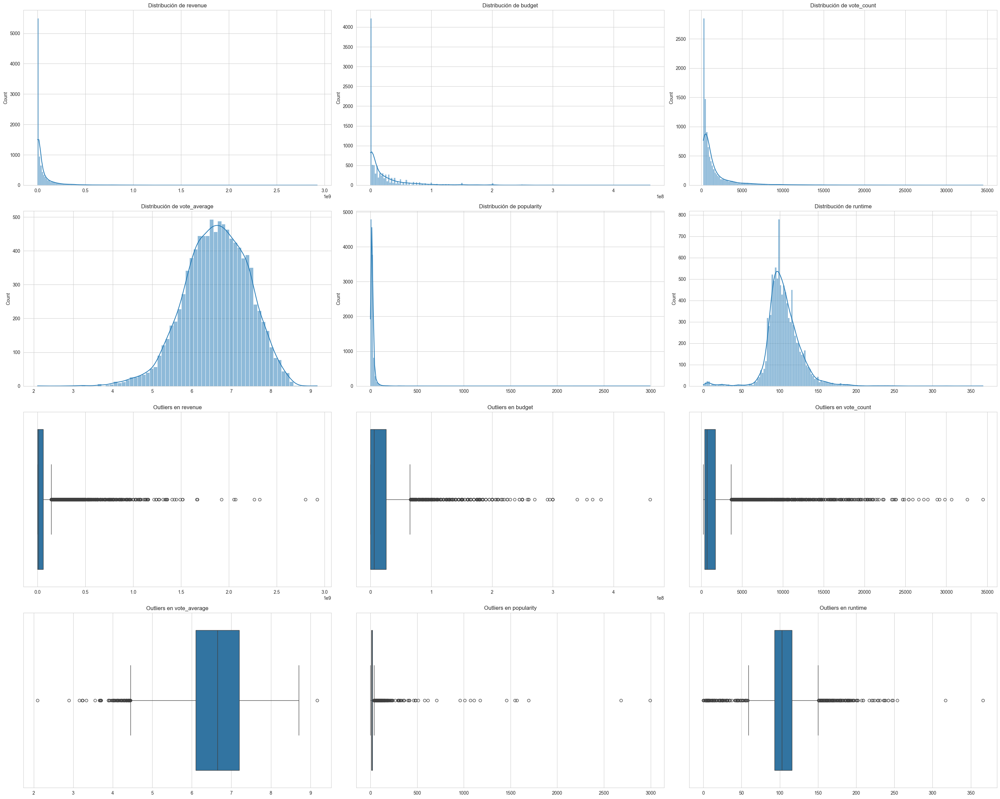

In [18]:
fig, axes = plt.subplots(4, 3, figsize=(30, 24))

for i, col in enumerate(numerical_features):
    data = df.select(col).collect().to_series()
    sns.histplot(data, kde=True, ax=axes[i//3, i%3])
    axes[i//3, i%3].set_title(f'Distribución de {col}')
    axes[i//3, i%3].set_xlabel('')
    sns.boxplot(x=data, ax=axes[2 + i//3, i%3])
    axes[2 + i//3, i%3].set_xlabel('')
    axes[2 + i//3, i%3].set_title(f'Outliers en {col}')

plt.tight_layout()
plt.show()

### Variables categóricas

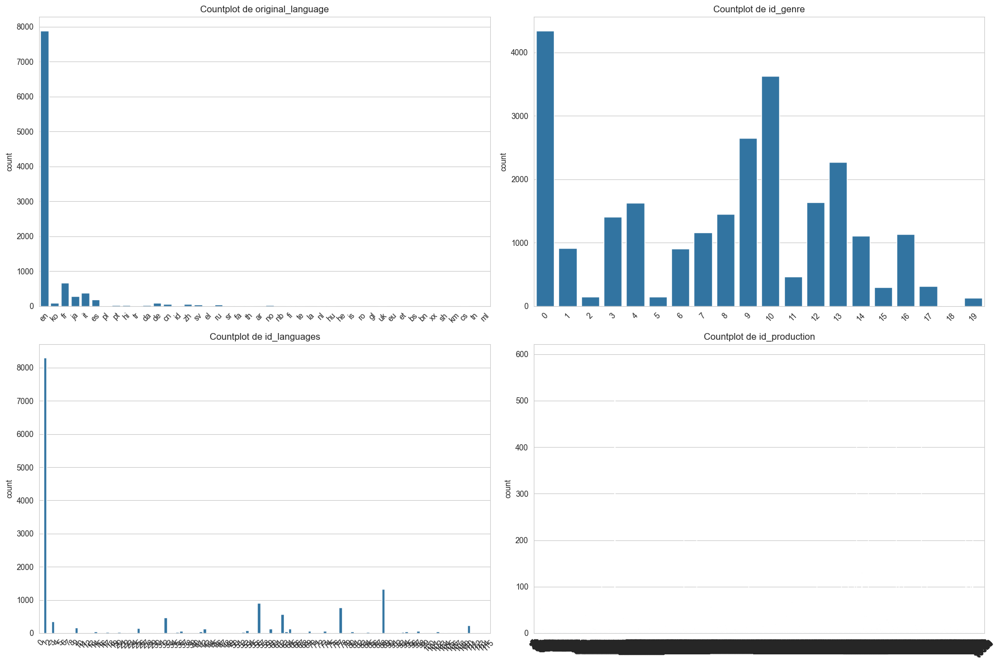

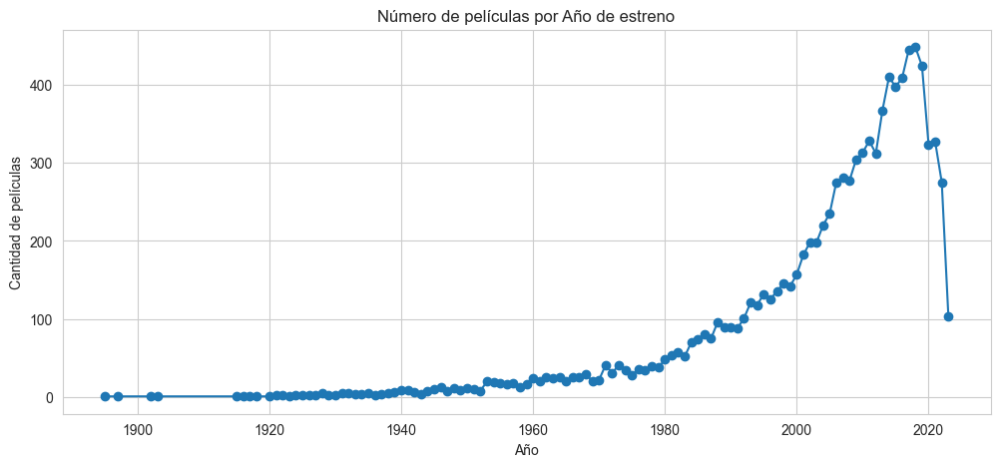

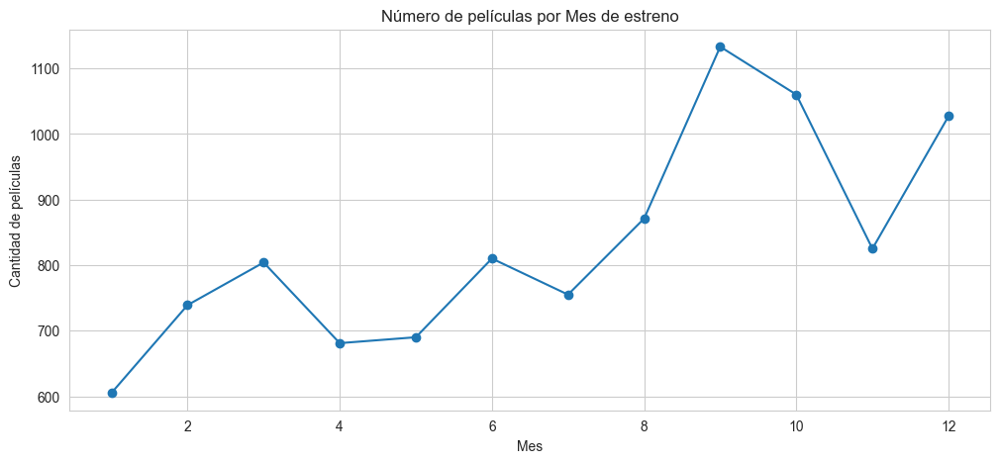

In [19]:
categorical = ['original_language', 'id_genre', 'id_languages', 'id_production']  # excluimos country, year, month

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(categorical):
    series = movies_df_final.select(col).collect().to_series()

    if series[0].__class__ in [list, pl.Series]:
        series = series.explode()

    sns.countplot(x=series, ax=axes[i])
    axes[i].set_title(f'Countplot de {col}')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

release_df = movies_df_final.select(['release_year', 'release_month']).collect().to_pandas()

# Año
plt.figure(figsize=(12, 5))
release_counts = release_df['release_year'].value_counts().sort_index()
plt.plot(release_counts.index, release_counts.values, marker='o')
plt.title('Número de películas por Año de estreno')
plt.xlabel('Año')
plt.ylabel('Cantidad de películas')
plt.grid(True)
plt.show()

# Mes
plt.figure(figsize=(12, 5))
month_counts = release_df['release_month'].value_counts().sort_index()
plt.plot(month_counts.index, month_counts.values, marker='o')
plt.title('Número de películas por Mes de estreno')
plt.xlabel('Mes')
plt.ylabel('Cantidad de películas')
plt.grid(True)
plt.show()

## Selección variables

Siendo revenue la variable objetivo, a continuación se realiza un análisis de correlaciones y pruebas de ANOVA para seleccionar las variables que tienen mayor relación y, por tanto, son más relevantes para incluir en el modelo predictivo.

### Matriz de correlaciones

In [20]:
movies_df_collected = movies_df_final.collect()

corr_matrix = movies_df_collected.select(numerical_features).corr()
display(corr_matrix)

revenue,budget,vote_count,vote_average,popularity,runtime
f64,f64,f64,f64,f64,f64
1.0,0.74408,0.748859,0.118703,0.206844,0.238248
0.74408,1.0,0.588316,-0.023266,0.210099,0.276373
0.748859,0.588316,1.0,0.262897,0.158171,0.249885
0.118703,-0.023266,0.262897,1.0,0.0875,0.240693
0.206844,0.210099,0.158171,0.0875,1.0,0.072387
0.238248,0.276373,0.249885,0.240693,0.072387,1.0


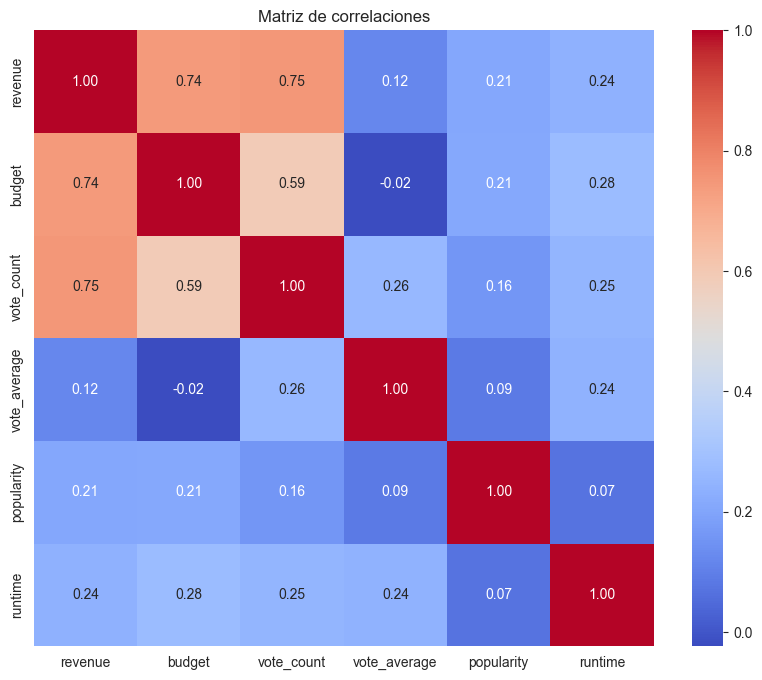

In [21]:
corr_pd = corr_matrix.to_pandas()
corr_pd.index = corr_pd.columns

plt.figure(figsize=(10, 8))
sns.heatmap(corr_pd, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlaciones")
plt.show()

### Test One-way Anova Género

In [22]:
rows = []

for var in numerical_features:
    samples_df = movies_df_collected.select(["id_genre", var]).explode("id_genre").drop_nulls()

    samples = (
        samples_df
        .group_by("id_genre")
        .agg(pl.col(var))
        .select(var)
        .to_series()
        .to_list()
    )

    f_stat, p_value = f_oneway(*samples)

    rows.append({
        "variable": var,
        "F": f_stat,
        "p_value": p_value
    })

anova_table = (
    pl.DataFrame(rows)
    .with_columns([
        pl.col("F").round(3),
        pl.col("p_value"),
        (pl.col("p_value") < 0.05).alias("significant")
    ])
)

display(anova_table)


variable,F,p_value,significant
str,f64,f64,bool
"""revenue""",77.876,5.1934e-294,true
"""budget""",128.973,0.0,true
"""vote_count""",51.968,1.9652e-193,true
"""vote_average""",124.11,0.0,true
"""popularity""",11.22,1.1622e-34,true
"""runtime""",208.882,0.0,true


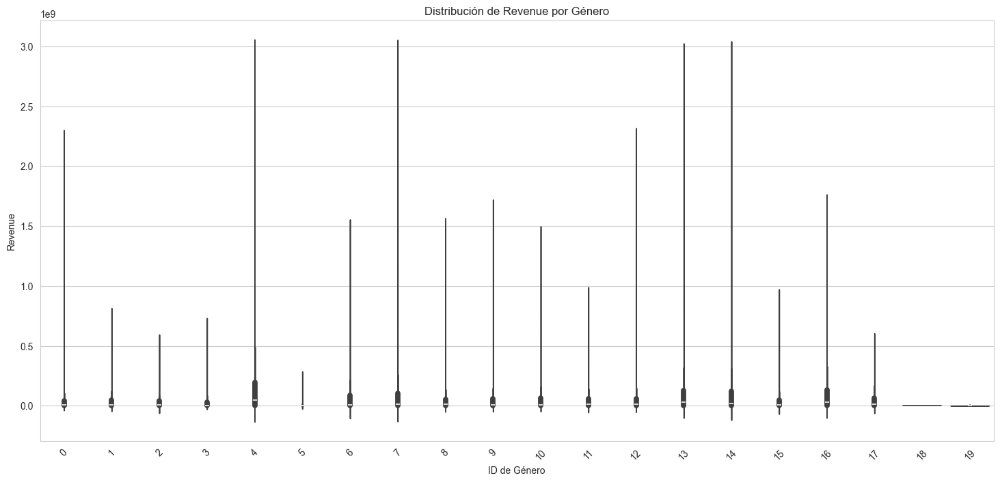

In [23]:
revenue_by_genre = movies_df_collected.select(["id_genre", "revenue"]).explode("id_genre")

revenue_by_genre_pd = revenue_by_genre.to_pandas()

plt.figure(figsize=(18, 8))
sns.violinplot(
    x="id_genre",
    y="revenue",
    data=revenue_by_genre_pd
)
plt.title("Distribución de Revenue por Género")
plt.xlabel("ID de Género")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

### Test One-way Anova Idioma original

In [24]:
from scipy.stats import f_oneway
import polars as pl

lf = movies_df_collected

numeric_vars = [
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity"
]

rows = []

for var in numeric_vars:
    samples = (
        lf
        .select(["original_language", var])
        .drop_nulls()
        .group_by("original_language")
        .agg(pl.col(var))
        .select(var)
        .to_series()
        .to_list()
    )

    # Test ANOVA
    f_stat, p_value = f_oneway(*samples)

    rows.append({
        "variable": var,
        "F": f_stat,
        "p_value": p_value
    })

anova_table = (
    pl.DataFrame(rows)
    .with_columns([
        pl.col("F").round(3),
        pl.col("p_value").round(5),
        (pl.col("p_value") < 0.05).alias("significant")
    ])
)

display(anova_table)


variable,F,p_value,significant
str,f64,f64,bool
"""vote_average""",18.451,0.0,true
"""vote_count""",8.102,0.0,true
"""revenue""",7.551,0.0,true
"""runtime""",9.914,0.0,true
"""budget""",14.633,0.0,true
"""popularity""",1.387,0.04768,true


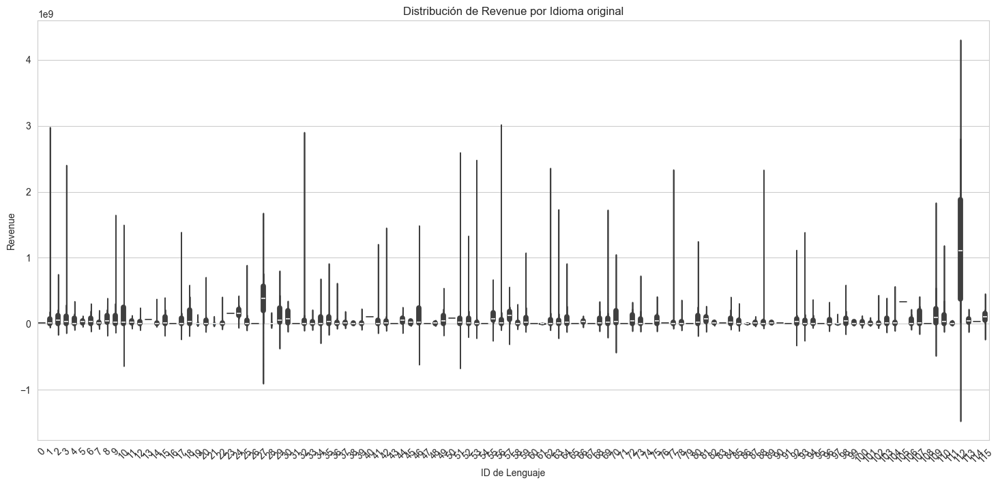

In [25]:
revenue_by_language = movies_df_collected.select(["id_languages", "revenue"]).explode("id_languages")

revenue_by_language_pd = revenue_by_language.to_pandas()

plt.figure(figsize=(18, 8))
sns.violinplot(
    x="id_languages",
    y="revenue",
    data=revenue_by_language_pd
)
plt.title("Distribución de Revenue por Idioma original")
plt.xlabel("ID de Lenguaje")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Después de realizar el análisis de correlaciones y test de anova, seleccionamos las siguientes variables para nuestro modelo: vote_count, budget, id_genre y original_language.

## Modelo

In [29]:
h2o.init()

# Convertir a H2OFrame desde pandas
df_h2o = h2o.H2OFrame(movies_df_final.collect().to_pandas())

# Definir target y predictores
target = "revenue"
predictors = ["id_genre", "original_language", "vote_count", "budget"]

# Dividir en train y test
train, test = df_h2o.split_frame(ratios=[0.8], seed=42)

# Entrenar AutoML
aml = H2OAutoML(max_models=10, seed=42, project_name="vote_prediction")
aml.train(x=predictors, y=target, training_frame=train)

# Mostrar leaderboard completo
lb = aml.leaderboard
display(lb.head(rows=lb.nrows))


Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,6 mins 30 secs
H2O_cluster_timezone:,Europe/Madrid
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.9
H2O_cluster_version_age:,2 months and 23 days
H2O_cluster_name:,H2O_from_python_agusti_costabella_nzo3fr
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,7.593 Gb
H2O_cluster_total_cores:,8
H2O_cluster_allowed_cores:,8
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |██
20:42:38.657: AutoML: XGBoost is not available; skipping it.

█████████████████████████████████████████████████████████████| (done) 100%


model_id,rmse,mse,mae,rmsle,mean_residual_deviance
StackedEnsemble_AllModels_1_AutoML_1_20260216_204238,7.91999e+07,6.27262e+15,3.39853e+07,nan,6.27262e+15
StackedEnsemble_BestOfFamily_1_AutoML_1_20260216_204238,7.94222e+07,6.30788e+15,3.47396e+07,nan,6.30788e+15
GBM_grid_1_AutoML_1_20260216_204238_model_1,7.94435e+07,6.31128e+15,3.44783e+07,nan,6.31128e+15
GBM_2_AutoML_1_20260216_204238,8.15746e+07,6.65442e+15,3.4118e+07,nan,6.65442e+15
GBM_5_AutoML_1_20260216_204238,8.21066e+07,6.74149e+15,3.44181e+07,nan,6.74149e+15
GBM_3_AutoML_1_20260216_204238,8.24191e+07,6.79291e+15,3.43109e+07,nan,6.79291e+15
GBM_4_AutoML_1_20260216_204238,8.37374e+07,7.01195e+15,3.44039e+07,nan,7.01195e+15
GBM_1_AutoML_1_20260216_204238,8.54728e+07,7.3056e+15,3.49397e+07,nan,7.3056e+15
DeepLearning_1_AutoML_1_20260216_204238,8.6507e+07,7.48346e+15,4.40313e+07,nan,7.48346e+15
XRT_1_AutoML_1_20260216_204238,9.21219e+07,8.48644e+15,3.79878e+07,9.11243,8.48644e+15


In [30]:
best_model = aml.leader
perf = best_model.model_performance(test)

print("RMSE:", perf.rmse())
print("MAE:", perf.mae())
print("R2:", perf.r2())
print(aml.leaderboard)

RMSE: 76493583.68212333
MAE: 33233648.089369524
R2: 0.721295970685482
model_id                                                        rmse          mse          mae      rmsle    mean_residual_deviance
StackedEnsemble_AllModels_1_AutoML_1_20260216_204238     7.91999e+07  6.27262e+15  3.39853e+07  nan                     6.27262e+15
StackedEnsemble_BestOfFamily_1_AutoML_1_20260216_204238  7.94222e+07  6.30788e+15  3.47396e+07  nan                     6.30788e+15
GBM_grid_1_AutoML_1_20260216_204238_model_1              7.94435e+07  6.31128e+15  3.44783e+07  nan                     6.31128e+15
GBM_2_AutoML_1_20260216_204238                           8.15746e+07  6.65442e+15  3.4118e+07   nan                     6.65442e+15
GBM_5_AutoML_1_20260216_204238                           8.21066e+07  6.74149e+15  3.44181e+07  nan                     6.74149e+15
GBM_3_AutoML_1_20260216_204238                           8.24191e+07  6.79291e+15  3.43109e+07  nan                     6.79291e+15
GBM_4_

## Optimización

Finalmente, se realiza la optimización del modelo mediante GridSearch, encontrando así la mejor configuración de los hiperparámetros del modelo.

In [31]:
from h2o.estimators import H2OGradientBoostingEstimator
from h2o.grid.grid_search import H2OGridSearch

# Espacio de hiperparámetros
gbm_params = {
    "learn_rate": [0.01, 0.05],
    "max_depth": [5, 7],
    "sample_rate": [0.8, 1.0]
}

# Modelo base
gbm = H2OGradientBoostingEstimator(
    ntrees=700,
    seed=42,
    nfolds=5,
    stopping_rounds=5,
    stopping_metric="RMSE",
    stopping_tolerance=0.001
)

# Grid Search
grid = H2OGridSearch(
    model=gbm,
    grid_id="gbm_manual_optimization",
    hyper_params=gbm_params
)

grid.train(
    x=predictors,
    y=target,
    training_frame=train
)

# Ordenar por RMSE
grid_perf = grid.get_grid(sort_by="rmse", decreasing=False)

print("===== RESULTATS GRID =====")
print(grid_perf)

# Mejor modelo
best_gbm = grid_perf.models[0]

# Evaluación en test
perf_test = best_gbm.model_performance(test)

print("\n===== RESULTADOS TEST =====")
print("RMSE:", perf_test.rmse())
print("MAE:", perf_test.mae())
print("R2:", perf_test.r2())

gbm Grid Build progress: |███████████████████████████████████████████████████████| (done) 100%
===== RESULTATS GRID =====
Hyper-Parameter Search Summary: ordered by increasing rmse
    learn_rate    max_depth    sample_rate    model_ids                        rmse
--  ------------  -----------  -------------  -------------------------------  -----------
    0.05          5            1              gbm_manual_optimization_model_6  7.88742e+07
    0.05          5            0.8            gbm_manual_optimization_model_2  7.99566e+07
    0.01          5            1              gbm_manual_optimization_model_5  8.01521e+07
    0.01          5            0.8            gbm_manual_optimization_model_1  8.06511e+07
    0.05          7            0.8            gbm_manual_optimization_model_4  8.07768e+07
    0.01          7            0.8            gbm_manual_optimization_model_3  8.10654e+07
    0.05          7            1              gbm_manual_optimization_model_8  8.12976e+07
    0.0

## Evaluación

Finalmente, realizamos la evaluación del modelo.

In [ ]:
 # Evaluación del mejor modelo
perf = aml.leader.model_performance(test)
print(perf)